In [1]:
#looding and cleaning data.

In [ ]:
import pandas as pd
import glob
import os

from pathlib import Path

folder = Path("data")

csv_files = glob.glob(os.path.join(folder, "*.csv"))

olist_data = {}

for file in csv_files:
    name = os.path.basename(file).replace(".csv", "")
    olist_data[name] = pd.read_csv(file)

print("Number of CSV files loaded:", len(olist_data))
print("Files loaded:")

for name in olist_data:
    print(name)

Number of CSV files loaded: 12
Files loaded:
customers_202503150948
geolocation_202503150949
geolocation_ascii
leads_closed_202503150950
leads_qualified_202503150950
orders_202503150951
order_items_202503150951
order_payments_202503150951
order_reviews_202503150951
order_reviews_ascii
products_202503150952
sellers_202503150952


In [2]:
print(folder)

C:\Users\Veronica\OneDrive\Desktop\olist t


In [3]:
print(csv_files)

['C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\customers_202503150948.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\geolocation_202503150949.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\geolocation_ascii.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\leads_closed_202503150950.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\leads_qualified_202503150950.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\orders_202503150951.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\order_items_202503150951.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\order_payments_202503150951.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\order_reviews_202503150951.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\order_reviews_ascii.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\products_202503150952.csv', 'C:\\Users\\Veronica\\OneDrive\\Desktop\\olist t\\sellers_202503150952.csv']


In [4]:
print(olist_data.keys())

dict_keys(['customers_202503150948', 'geolocation_202503150949', 'geolocation_ascii', 'leads_closed_202503150950', 'leads_qualified_202503150950', 'orders_202503150951', 'order_items_202503150951', 'order_payments_202503150951', 'order_reviews_202503150951', 'order_reviews_ascii', 'products_202503150952', 'sellers_202503150952'])


In [5]:
reviews = olist_data["order_reviews_202503150951"]
items = olist_data["order_items_202503150951"]
products = olist_data["products_202503150952"]

In [6]:
# This Converts review dates and scores to the correct data types

reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"], errors="coerce")
reviews["review_answer_timestamp"] = pd.to_datetime( reviews["review_answer_timestamp"], errors="coerce")
reviews["review_score"] = pd.to_numeric( reviews["review_score"], errors="coerce")


In [7]:
#This will Check for missing review comments.

("Missing review comments:", reviews["review_comment_message"].isna().sum())

('Missing review comments:', np.int64(58247))

In [8]:
for name, df in {
    "reviews": reviews,
    "items": items,
    "products": products
}.items():
    print(f"{name}: {df.duplicated().sum()} exact duplicate rows")

reviews: 0 exact duplicate rows
items: 0 exact duplicate rows
products: 0 exact duplicate rows


In [10]:
# Q1  plot the Rewiew_score distribution(1-5) and report the share of 1–2 star reviews:

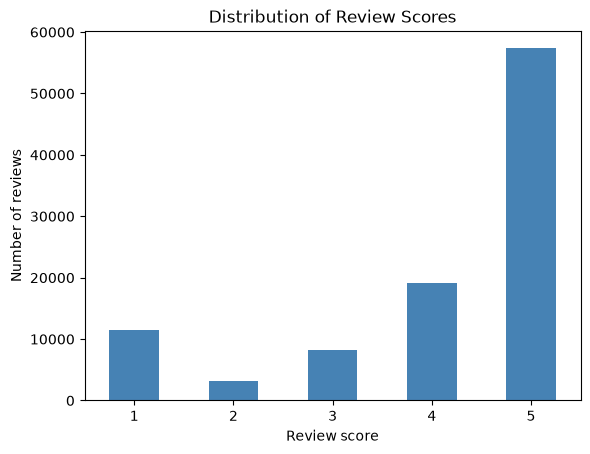

Share of 1–2 star reviews: 14.69%


In [9]:
import matplotlib.pyplot as plt

score_counts = reviews["review_score"].value_counts().reindex( [1, 2, 3, 4, 5], fill_value=0)

score_counts.plot(kind="bar", color="steelblue")
plt.title("Distribution of Review Scores")
plt.xlabel("Review score")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

valid_scores = reviews["review_score"].dropna()
low_star_share = valid_scores.isin([1, 2]).mean() * 100

print(f"Share of 1–2 star reviews: {low_star_share:.2f}%")

In [12]:
# This shows approximately 14.69% of valid reviews were low-rated, while 85.31% received 3,4,or5 stars.5star reviews were the most common.
#The review score distribution shows that 5star reviews were the most frequent, indicating generally positive customer feedback.However,14.69% 
#of valid reviews received 1 or 2 stars, this highlights an opportunity to investigate customer dissatisfaction and identify product categories that may require improvement.

In [13]:
# Q2 group the 1-2 star rewiews by product category and rank the 10 worst by both counts and rate

In [10]:
#this code does:
#Joins reviews to order items and products.
#Identifies 1–2 star reviews.
#Groups the data by product category.
#Calculates the number and rate of low-rated reviews.
#Ranks the ten categories by count and by rate.

review_categories = ( reviews[["review_id", "order_id", "review_score"]]
    .merge(items[["order_id", "product_id"]], on="order_id", how="inner")
    .merge(products[["product_id", "product_category_name"]],
        on="product_id",
        how="left")
    .dropna(subset=["product_category_name", "review_score"])
    .drop_duplicates(subset=["review_id", "product_category_name"]))

review_categories["low_score"] = review_categories["review_score"].isin([1, 2])

category_results = (
    review_categories.groupby("product_category_name")
    .agg( total_reviews=("low_score", "size"), low_reviews=("low_score", "sum") ))

category_results["low_review_rate"] = ( category_results["low_reviews"] / category_results["total_reviews"] * 100).round(2)

print("Ten categories with the most 1–2 star reviews:")
display(category_results.sort_values("low_reviews", ascending=False).head(10))

print("Ten categories with the highest 1–2 star review rate:")
display(category_results.sort_values("low_review_rate", ascending=False).head(10))

Ten categories with the most 1–2 star reviews:


,total_reviews,low_reviews,low_review_rate
product_category_name,,,
cama_mesa_banho,9324,1558,16.71
beleza_saude,8767,1112,12.68
moveis_decoracao,6404,1065,16.63
informatica_acessorios,6641,1061,15.98
esporte_lazer,7656,994,12.98
relogios_presentes,5582,848,15.19
utilidades_domesticas,5854,771,13.17
telefonia,4170,644,15.44
automotivo,3879,561,14.46


Ten categories with the highest 1–2 star review rate:


,total_reviews,low_reviews,low_review_rate
product_category_name,,,
seguros_e_servicos,2,1,50.00
pc_gamer,8,3,37.50
portateis_cozinha_e_preparadores_de_alimentos,14,4,28.57
fashion_roupa_masculina,111,29,26.13
moveis_escritorio,1265,287,22.69
audio,348,77,22.13
fashion_roupa_feminina,41,9,21.95
casa_conforto_2,23,5,21.74
moveis_colchao_e_estofado,38,8,21.05


In [15]:
#The cama_mesa_banho category has the highest count, with 1,558 low-rated reviews and a 16.71% low-review rate.
#Categories such as moveis_decoracao and informatica_acessorios also showed relatively high rates. 
#These findings can help prioritize further investigation into customer dissatisfaction. 
#Categories with very few reviews should be interpreted cautiously because small samples can produce unusually high percentages.
# N/B reviews are attached to orders,not individual products,thus these result does not identify which specific product prompted the rating.

In [16]:
# Customer Review Analysis

In [11]:
total_reviews = len(reviews)

average_score = reviews['review_score'].mean()

# Number of reviews for each score
review_counts = reviews['review_score'].value_counts().sort_index()

#  Percentage of five-star reviews
five_star_percentage = (
    reviews['review_score'].eq(5).mean() * 100)

# Percentage of one- and two-star reviews
low_review_percentage = (
    reviews['review_score'].isin([1, 2]).mean() * 100)

print("CUSTOMER REVIEW ANALYSIS")
print("-" * 35)

print(f"Total reviews: {total_reviews:,}")
print(f"Average review score: {average_score:.2f}/5")
print(f"Five-star reviews: {five_star_percentage:.2f}%")
print(f"One- and two-star reviews: {low_review_percentage:.2f}%")

print("\nReview counts by score:")
print(review_counts)



CUSTOMER REVIEW ANALYSIS
-----------------------------------
Total reviews: 99,224
Average review score: 4.09/5
Five-star reviews: 57.78%
One- and two-star reviews: 14.69%

Review counts by score:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


This shows that customer review dataset contains 99,224 reviews. The average review score is 4.09 out of 5, indicating generally positive customer feedback.

Five-star reviews represent 57.78% of all reviews, while one- and two-star reviews account for 14.69%. The distribution shows that most reviews are positive, but a meaningful proportion of customers gave low ratings.

These results provide a baseline for understanding customer satisfaction. The business should investigate negative feedback and examine whether delivery delays or product-related issues are associated with lower review scores.